# Leyes constitutivas tensión-deformación

Cuaderno de exploración de las leyes **σ–ε** implementadas en el proyecto:

- **Leyes generales**, independientes de cualquier norma:
  `domain/mechanics/generic_laws.py`.
- **Leyes del hormigón** de la familia Eurocódigo / Código Estructural:
  `norms/eurocode/laws.py` (EN 1992-1-1, §3.1.5 y §3.1.7).

**Convenio de signos:** deformaciones y tensiones positivas en tracción y
negativas en compresión.

**Unidades:** deformación adimensional (tanto por uno) y tensión en MPa. En las
gráficas la deformación se representa en ‰ para facilitar la lectura.

> Este cuaderno se ejecuta con el extra `notebooks`:
> `pip install -e ".[notebooks]"`. Las gráficas están embebidas, de modo que
> GitHub las muestra sin necesidad de ejecutar nada.


### Configuración del cuaderno

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

from placas_alveolares.domain.mechanics.generic_laws import (
    LeyElastica,
    LeyElastoplastica,
)
from placas_alveolares.domain.mechanics.laws import LeyTensionDeformacion
from placas_alveolares.domain.model.materiales import Hormigon
from placas_alveolares.norms.eurocode.laws import (
    deformaciones_tabla_3_1,
    ley_hormigon_bilineal,
    ley_hormigon_lineal,
    ley_hormigon_no_lineal,
    ley_hormigon_parabola,
)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 120,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def estilizar_eje(ax, titulo: str) -> None:
    """Aplica el formato común a una gráfica σ–ε."""
    ax.set_title(titulo)
    ax.set_xlabel("Deformación ε (‰)")
    ax.set_ylabel("Tensión σ (MPa)")
    ax.axhline(0.0, color="0.3", linewidth=0.8)
    ax.axvline(0.0, color="0.3", linewidth=0.8)


def dibujar_ley(
    ley: LeyTensionDeformacion,
    ax,
    desde: float,
    hasta: float,
    titulo: str,
    *,
    puntos: int = 1201,
    color: str = "tab:blue",
) -> None:
    """Dibuja una ley constitutiva en el eje indicado."""
    deformaciones = np.linspace(desde, hasta, puntos)
    tensiones = np.array([ley.tension(float(e)) for e in deformaciones])
    ax.plot(deformaciones * 1000.0, tensiones, color=color, linewidth=2.0)
    estilizar_eje(ax, titulo)


def marcar_deformacion(
    ax, deformacion: float, etiqueta: str | None = None
) -> None:
    """Marca una deformación característica con una línea vertical."""
    ax.axvline(
        deformacion * 1000.0,
        color="0.45",
        linestyle=":",
        linewidth=1.0,
    )
    if etiqueta is not None:
        ax.annotate(
            etiqueta,
            xy=(deformacion * 1000.0, 0.0),
            xytext=(3.0, 5.0),
            textcoords="offset points",
            fontsize=8,
            color="0.35",
        )


## 1. Leyes generales

Son leyes **físicas**, no normativas. El dominio define el contrato
`LeyTensionDeformacion` y estas implementaciones permiten analizar y probar los
motores mecánicos sin depender de una norma concreta.

- **Ley elástica lineal (Hooke):** $\sigma = E\,\varepsilon$.
- **Ley elastoplástica perfecta:** rama lineal hasta $f_y$, meseta plástica y
  tensión nula a partir de la deformación última $\varepsilon_u$.

La segunda es la forma habitual para el acero de armadura: $E_s = 200\,000$ MPa,
$f_y = 500$ MPa y $\varepsilon_u = 0{,}05$.


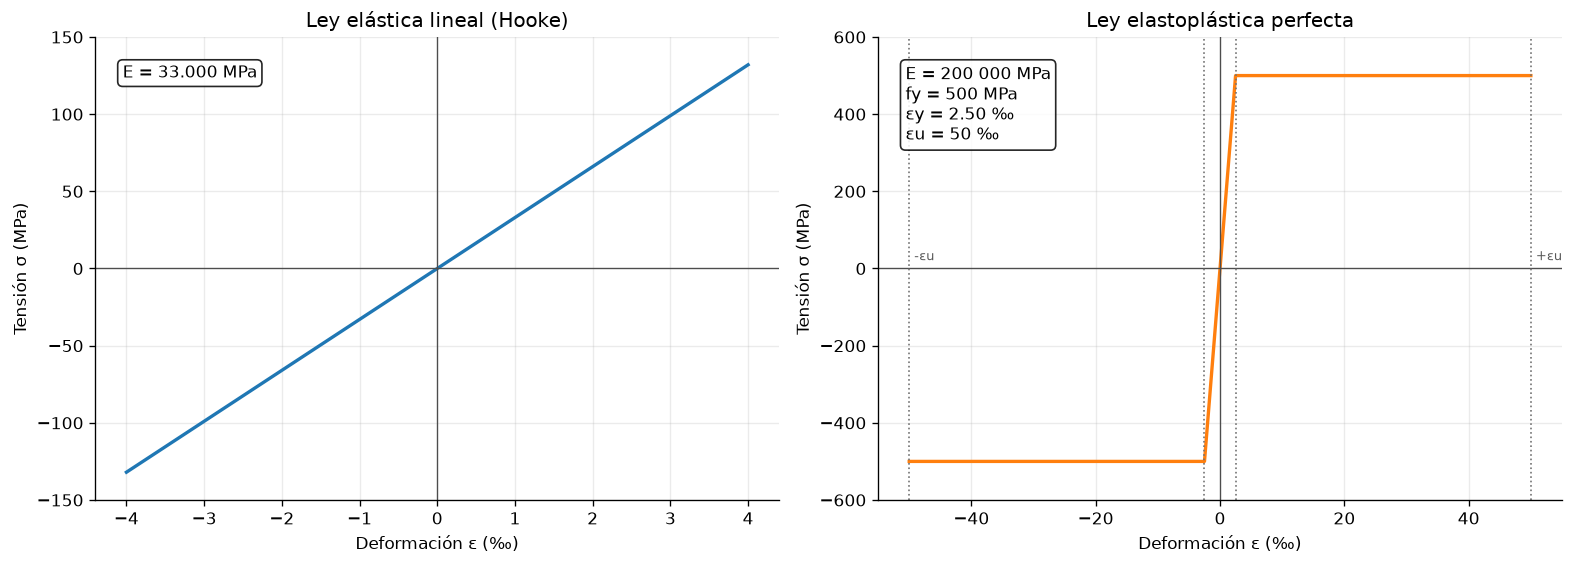

In [2]:
ley_elastica = LeyElastica(modulo_elasticidad=33_000.0)

ley_elastoplastica = LeyElastoplastica(
    modulo_elasticidad=200_000.0,
    limite_elastico=500.0,
    deformacion_ultima=0.05,
)

fig, (ax_hooke, ax_acero) = plt.subplots(
    1, 2, figsize=(13, 4.6), constrained_layout=True
)

dibujar_ley(
    ley_elastica,
    ax_hooke,
    -0.004,
    0.004,
    "Ley elástica lineal (Hooke)",
    color="tab:blue",
)
ax_hooke.set_ylim(-150.0, 150.0)
ax_hooke.text(
    0.04,
    0.94,
    f"E = {ley_elastica.modulo_elasticidad:,.0f} MPa".replace(",", "."),
    transform=ax_hooke.transAxes,
    va="top",
    fontsize=10,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "alpha": 0.85},
)

dibujar_ley(
    ley_elastoplastica,
    ax_acero,
    ley_elastoplastica.deformacion_maxima_compresion,
    ley_elastoplastica.deformacion_maxima_traccion,
    "Ley elastoplástica perfecta",
    color="tab:orange",
)
ax_acero.set_ylim(-600.0, 600.0)

deformacion_fluencia = (
    ley_elastoplastica.limite_elastico
    / ley_elastoplastica.modulo_elasticidad
)
marcar_deformacion(ax_acero, -ley_elastoplastica.deformacion_ultima, "-εu")
marcar_deformacion(ax_acero, -deformacion_fluencia)
marcar_deformacion(ax_acero, deformacion_fluencia)
marcar_deformacion(ax_acero, ley_elastoplastica.deformacion_ultima, "+εu")
ax_acero.text(
    0.04,
    0.94,
    "E = 200 000 MPa\n"
    f"fy = {ley_elastoplastica.limite_elastico:.0f} MPa\n"
    f"εy = {deformacion_fluencia * 1000:.2f} ‰\n"
    f"εu = {ley_elastoplastica.deformacion_ultima * 1000:.0f} ‰",
    transform=ax_acero.transAxes,
    va="top",
    fontsize=10,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "alpha": 0.85},
)

plt.show()


## 2. Leyes del hormigón (EN 1992-1-1)

El módulo `norms/eurocode/laws.py` implementa las cuatro leyes del hormigón
compartidas por el Eurocódigo 2 y el Código Estructural:

1. **Lineal elástica** (§3.1.5) con el módulo secante $E_{cm}$.
2. **Parábola-rectángulo** (§3.1.7(1), figura 3.3) para ELU.
3. **Bilineal** (§3.1.7(2), figura 3.4) para ELU.
4. **General no lineal** (§3.1.5, ecuación 3.14, figura 3.2), con rama
   descendente.

Las deformaciones características se obtienen de la **Tabla 3.1** a partir de
`fck` y `fcm`. Las leyes de cálculo usan $f_{cd} = f_{ck}/\gamma_c$; la ley
general no lineal usa valores medios $f_{cm}$ y $E_{cm}$.


### Deformaciones características (Tabla 3.1)

In [3]:
hormigon = Hormigon(fck=30.0, fcm=38.0, ecm=33_000.0)
gamma_c = 1.5

deformaciones = deformaciones_tabla_3_1(hormigon.fck, hormigon.fcm)

print("Hormigón C30/37")
print(f"  fck = {hormigon.fck:.1f} MPa")
print(f"  fcm = {hormigon.fcm:.1f} MPa")
print(f"  Ecm = {hormigon.ecm:,.0f} MPa".replace(",", "."))
print(f"  fcd = fck / γc = {hormigon.fck / gamma_c:.2f} MPa")
print()
print(f"{'Magnitud':<34}{'Valor':>12}")
print("-" * 46)
for nombre, valor in (
    ("εc1  (pico del diagrama general)", deformaciones.eps_c1),
    ("εcu1 (última del diagrama general)", deformaciones.eps_cu1),
    ("εc2  (pico parábola-rectángulo)", deformaciones.eps_c2),
    ("εcu2 (última parábola-rectángulo)", deformaciones.eps_cu2),
    ("εc3  (pico diagrama bilineal)", deformaciones.eps_c3),
    ("εcu3 (última diagrama bilineal)", deformaciones.eps_cu3),
):
    print(f"{nombre:<34}{valor * 1000:>9.3f} ‰")
print(f"{'n    (exponente parábola)':<34}{deformaciones.exponente:>12.3f}")


Hormigón C30/37
  fck = 30.0 MPa
  fcm = 38.0 MPa
  Ecm = 33.000 MPa
  fcd = fck / γc = 20.00 MPa

Magnitud                                 Valor
----------------------------------------------
εc1  (pico del diagrama general)      2.162 ‰
εcu1 (última del diagrama general)    3.500 ‰
εc2  (pico parábola-rectángulo)       2.000 ‰
εcu2 (última parábola-rectángulo)     3.500 ‰
εc3  (pico diagrama bilineal)         1.750 ‰
εcu3 (última diagrama bilineal)       3.500 ‰
n    (exponente parábola)                2.000


### Las cuatro leyes del hormigón

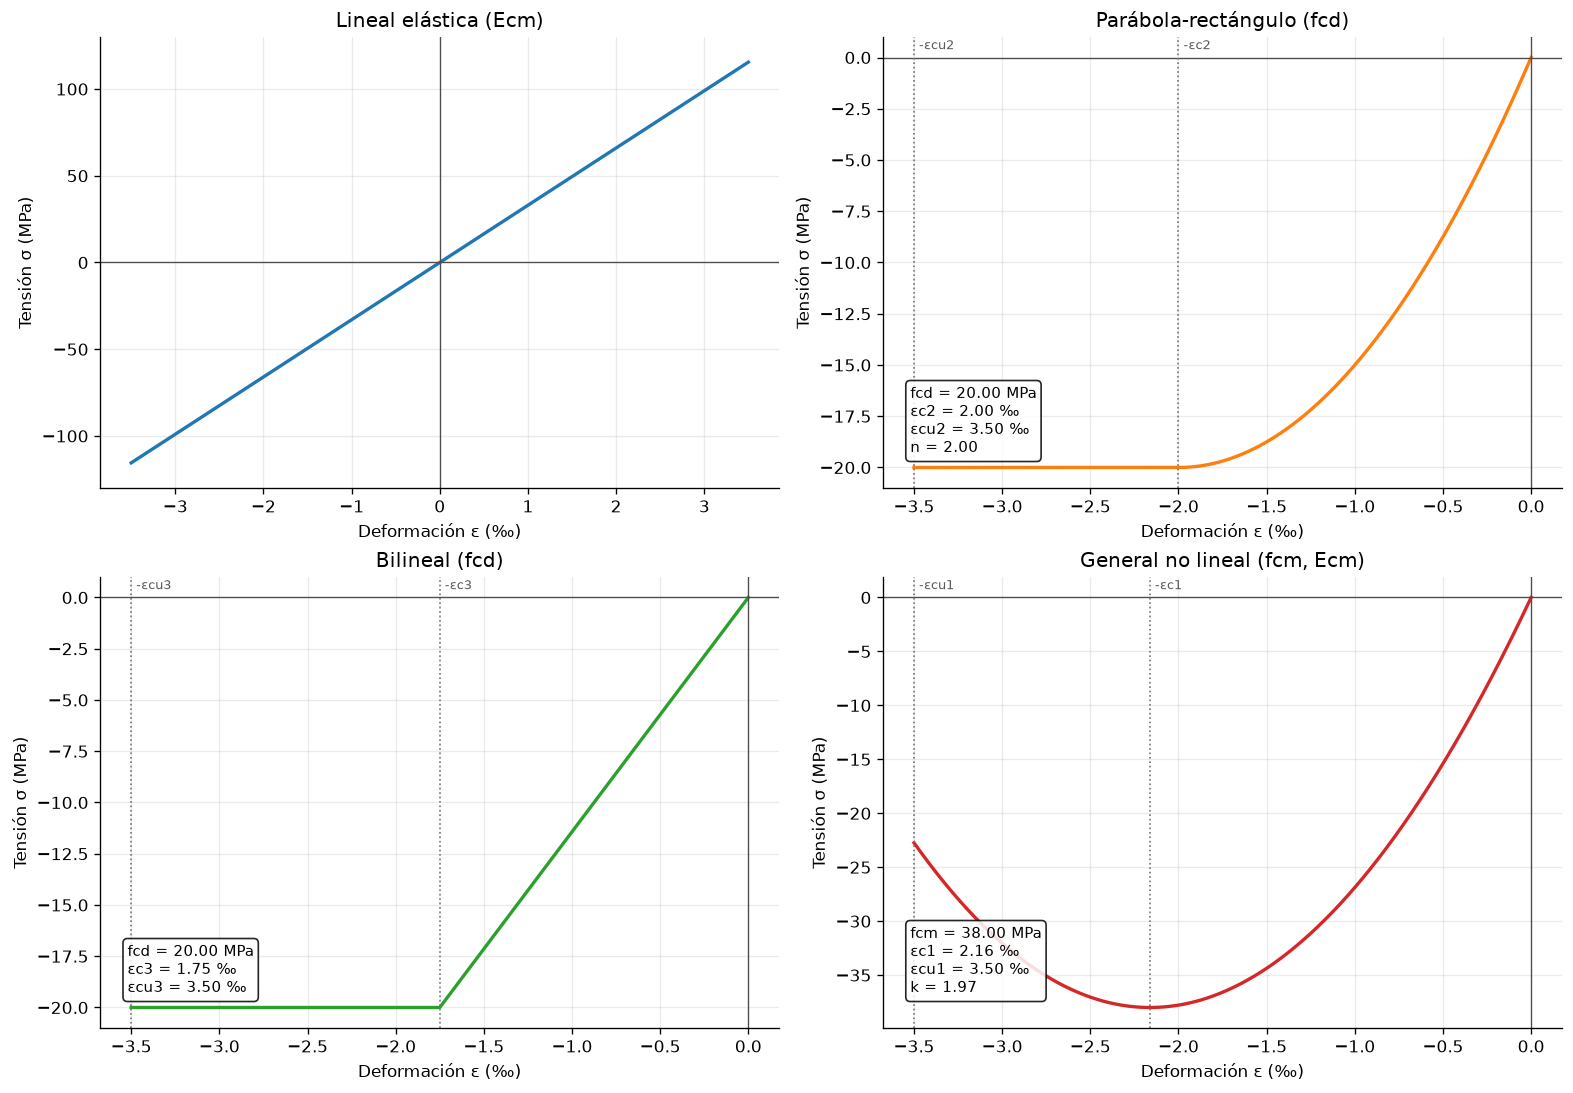

In [4]:
ley_lineal = ley_hormigon_lineal(hormigon)
ley_parabola = ley_hormigon_parabola(hormigon, gamma_c)
ley_bilineal = ley_hormigon_bilineal(hormigon, gamma_c)
ley_no_lineal = ley_hormigon_no_lineal(hormigon)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
ax_lineal, ax_parabola, ax_bilineal, ax_no_lineal = axes.ravel()

dibujar_ley(
    ley_lineal,
    ax_lineal,
    -0.0035,
    0.0035,
    "Lineal elástica (Ecm)",
    color="tab:blue",
)
ax_lineal.set_ylim(-130.0, 130.0)

dibujar_ley(
    ley_parabola,
    ax_parabola,
    ley_parabola.deformacion_maxima_compresion,
    ley_parabola.deformacion_maxima_traccion,
    "Parábola-rectángulo (fcd)",
    color="tab:orange",
)
marcar_deformacion(ax_parabola, -ley_parabola.eps_c2, "-εc2")
marcar_deformacion(ax_parabola, -ley_parabola.eps_cu2, "-εcu2")
ax_parabola.text(
    0.04,
    0.08,
    f"fcd = {ley_parabola.fc:.2f} MPa\n"
    f"εc2 = {ley_parabola.eps_c2 * 1000:.2f} ‰\n"
    f"εcu2 = {ley_parabola.eps_cu2 * 1000:.2f} ‰\n"
    f"n = {ley_parabola.exponente:.2f}",
    transform=ax_parabola.transAxes,
    fontsize=9,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "alpha": 0.85},
)

dibujar_ley(
    ley_bilineal,
    ax_bilineal,
    ley_bilineal.deformacion_maxima_compresion,
    ley_bilineal.deformacion_maxima_traccion,
    "Bilineal (fcd)",
    color="tab:green",
)
marcar_deformacion(ax_bilineal, -ley_bilineal.eps_c3, "-εc3")
marcar_deformacion(ax_bilineal, -ley_bilineal.eps_cu3, "-εcu3")
ax_bilineal.text(
    0.04,
    0.08,
    f"fcd = {ley_bilineal.fc:.2f} MPa\n"
    f"εc3 = {ley_bilineal.eps_c3 * 1000:.2f} ‰\n"
    f"εcu3 = {ley_bilineal.eps_cu3 * 1000:.2f} ‰",
    transform=ax_bilineal.transAxes,
    fontsize=9,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "alpha": 0.85},
)

dibujar_ley(
    ley_no_lineal,
    ax_no_lineal,
    ley_no_lineal.deformacion_maxima_compresion,
    ley_no_lineal.deformacion_maxima_traccion,
    "General no lineal (fcm, Ecm)",
    color="tab:red",
)
marcar_deformacion(ax_no_lineal, -ley_no_lineal.eps_c1, "-εc1")
marcar_deformacion(ax_no_lineal, -ley_no_lineal.eps_cu1, "-εcu1")
ax_no_lineal.text(
    0.04,
    0.08,
    f"fcm = {ley_no_lineal.fc:.2f} MPa\n"
    f"εc1 = {ley_no_lineal.eps_c1 * 1000:.2f} ‰\n"
    f"εcu1 = {ley_no_lineal.eps_cu1 * 1000:.2f} ‰\n"
    f"k = {ley_no_lineal.k:.2f}",
    transform=ax_no_lineal.transAxes,
    fontsize=9,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "alpha": 0.85},
)

plt.show()


### Comparativa

Las tres leyes de cálculo (parábola-rectángulo, bilineal y general no lineal)
comparten la misma resistencia de compresión de cálculo $f_{cd}$, pero difieren
en la forma de la rama ascendente y en la deformación última. La ley general no
lineal se dibuja con valores medios $f_{cm}$ y presenta rama descendente.


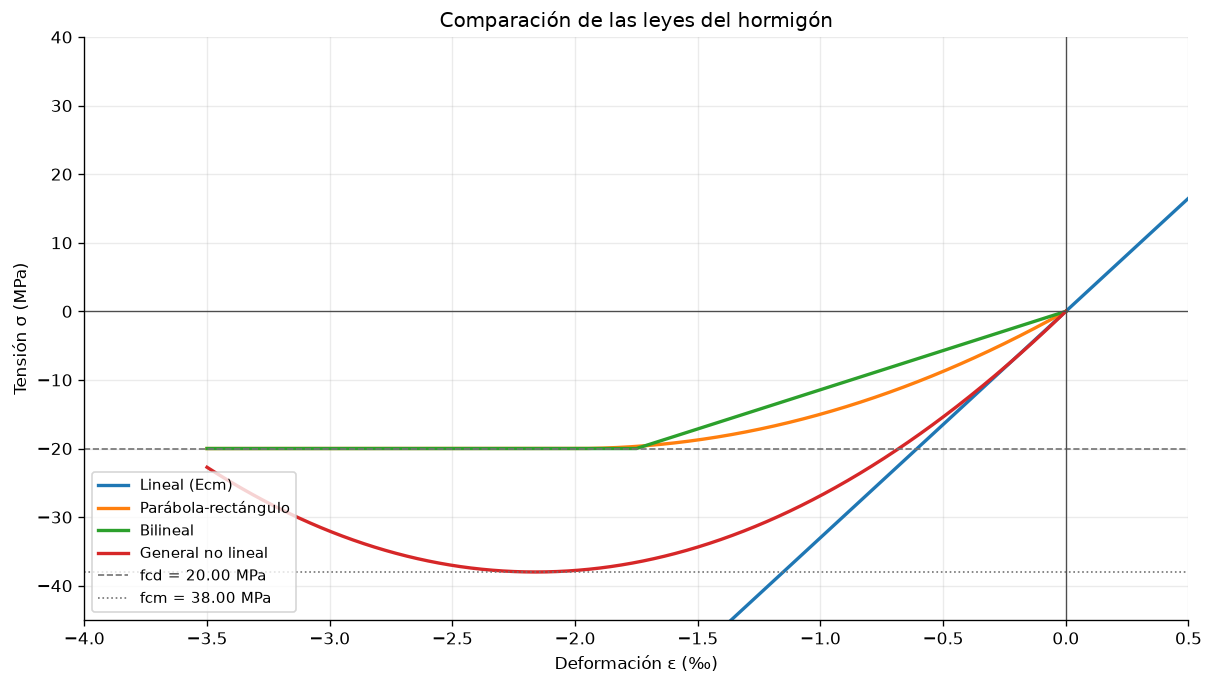

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.6), constrained_layout=True)

for ley, nombre, color in (
    (ley_lineal, "Lineal (Ecm)", "tab:blue"),
    (ley_parabola, "Parábola-rectángulo", "tab:orange"),
    (ley_bilineal, "Bilineal", "tab:green"),
    (ley_no_lineal, "General no lineal", "tab:red"),
):
    desde = ley.deformacion_maxima_compresion
    if not np.isfinite(desde):
        desde = -0.004
    hasta = min(0.0005, ley.deformacion_maxima_traccion)
    deformaciones_ley = np.linspace(desde, hasta, 1201)
    tensiones = np.array([ley.tension(float(e)) for e in deformaciones_ley])
    ax.plot(
        deformaciones_ley * 1000.0,
        tensiones,
        label=nombre,
        color=color,
        linewidth=2.0,
    )

ax.axhline(
    -ley_parabola.fc,
    color="0.45",
    linestyle="--",
    linewidth=1.0,
    label=f"fcd = {ley_parabola.fc:.2f} MPa",
)
ax.axhline(
    -ley_no_lineal.fc,
    color="0.45",
    linestyle=":",
    linewidth=1.0,
    label=f"fcm = {ley_no_lineal.fc:.2f} MPa",
)

estilizar_eje(ax, "Comparación de las leyes del hormigón")
ax.set_xlim(-4.0, 0.5)
ax.set_ylim(-45.0, 40.0)
ax.legend(loc="lower left", fontsize=9)

plt.show()


## Cómo ejecutar el cuaderno

```powershell
.venv\Scripts\activate
pip install -e ".[notebooks]"
jupyter nbconvert --execute --to notebook --inplace notebooks/leyes_constitutivas.ipynb
```

El cuaderno está pensado para **leerse en GitHub** con las gráficas ya embebidas.
Si se editan los parámetros (`fck`, `fcm`, `Ecm`, `gamma_c`), basta con volver a
ejecutarlo para actualizar las salidas.
